# Lab 02 — Embeddings, recurrence and positions

**Book sections:** [0.6 Embeddings](../../book/docs/chapters/00-foundations/embeddings.md),
[0.7 Sequence modelling](../../book/docs/chapters/00-foundations/sequence-models.md),
[2.3 Positional encodings](../../book/docs/chapters/02-transformers/positions.md).

**Goal.** (1) See that an embedding layer is a one-hot matrix product; (2) train a skip-gram model on
depot instructions and inspect the geometry it learns; (3) measure vanishing/exploding gradients in an
RNN; (4) implement sinusoidal and rotary position encodings and verify their key properties.

**Runtime:** ≈1 minute on CPU. **Seed:** 0.

In [1]:
import math
import re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from vlacourse.data.instructions import COLORS, OBJECTS, instruction_corpus
from vlacourse.seed import set_seed

set_seed(0)

## 1. An embedding is a linear layer on one-hot vectors

In [2]:
V, d = 50, 8
emb = nn.Embedding(V, d)
ids = torch.tensor([[3, 7, 7, 1]])                      # (B, T) = (1, 4); token 7 appears twice
X = emb(ids)                                            # (1, 4, 8)
onehot = F.one_hot(ids, V).float()                      # (1, 4, 50)
print("lookup == one-hot @ E:", torch.allclose(onehot @ emb.weight, X))

# Gradient: only rows of tokens present in the batch receive gradient; repeated tokens accumulate.
X.sum().backward()
rows_with_grad = (emb.weight.grad.abs().sum(1) > 0).nonzero().flatten().tolist()
print("rows with gradient:", rows_with_grad)
print("grad row 7 / grad row 3 (token 7 used twice):", (emb.weight.grad[7] / emb.weight.grad[3]).tolist())

lookup == one-hot @ E: True
rows with gradient: [1, 3, 7]
grad row 7 / grad row 3 (token 7 used twice): [2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0]


## 2. Skip-gram on the depot corpus

Predict each context word $c$ (within a window of 2) from the centre word $w$:
$p(c\mid w)=\mathrm{softmax}(\mathbf u_w C^\top)_c$. The vocabulary is small, so we use the full softmax.

In [3]:
corpus = instruction_corpus(5000, seed=0)
words = [re.findall(r"[a-z]+", s.lower()) for s in corpus]
counts = Counter(w for s in words for w in s)
itos = sorted(counts)
stoi = {w: i for i, w in enumerate(itos)}
pairs = [(stoi[s[i]], stoi[s[j]]) for s in words for i in range(len(s))
         for j in range(max(0, i - 2), min(len(s), i + 3)) if j != i]
pairs = torch.tensor(pairs)
print(f"vocabulary {len(itos)} words, {len(pairs)} (centre, context) pairs")


class SkipGram(nn.Module):
    def __init__(self, V, d=16):
        super().__init__()
        self.U = nn.Embedding(V, d)   # centre-word embeddings: the ones we keep
        self.C = nn.Embedding(V, d)   # context embeddings

    def forward(self, w):             # w: (B,) -> logits (B, V)
        return self.U(w) @ self.C.weight.T


sg = SkipGram(len(itos))
opt = torch.optim.Adam(sg.parameters(), lr=1e-2)
g = torch.Generator().manual_seed(0)
for step in range(3000):
    b = pairs[torch.randint(0, len(pairs), (512,), generator=g)]
    loss = F.cross_entropy(sg(b[:, 0]), b[:, 1])
    opt.zero_grad(); loss.backward(); opt.step()
    if step % 1000 == 0 or step == 2999:
        print(f"step {step:4d}  loss {loss.item():.3f}   (uniform would be {math.log(len(itos)):.3f})")

vocabulary 80 words, 147236 (centre, context) pairs


step    0  loss 10.096   (uniform would be 4.382)


step 1000  loss 2.657   (uniform would be 4.382)


step 2000  loss 2.700   (uniform would be 4.382)


step 2999  loss 2.722   (uniform would be 4.382)


### Nearest neighbours by cosine similarity
Words that occur in the same slots of the grammar (colours, objects, places) should cluster.

In [4]:
E = F.normalize(sg.U.weight.detach(), dim=1)          # (V, d), unit rows: dot product = cosine


def neighbours(word, k=5):
    sims = E @ E[stoi[word]]
    best = sims.argsort(descending=True)[1:k + 1]
    return [(itos[i], round(sims[i].item(), 2)) for i in best]


for w in ["red", "toolbox", "drone", "survey"]:
    print(f"{w:8} -> {neighbours(w)}")

red      -> [('white', 0.98), ('blue', 0.98), ('green', 0.97), ('yellow', 0.97), ('black', 0.93)]
toolbox  -> [('barrel', 0.93), ('pallet', 0.92), ('panel', 0.88), ('ladder', 0.79), ('cone', 0.79)]
drone    -> [('all', 0.72), ('east', 0.63), ('west', 0.63), ('rover', 0.58), ('two', 0.57)]
survey   -> [('cover', 0.98), ('searches', 0.95), ('follow', 0.77), ('while', 0.77), ('near', 0.64)]


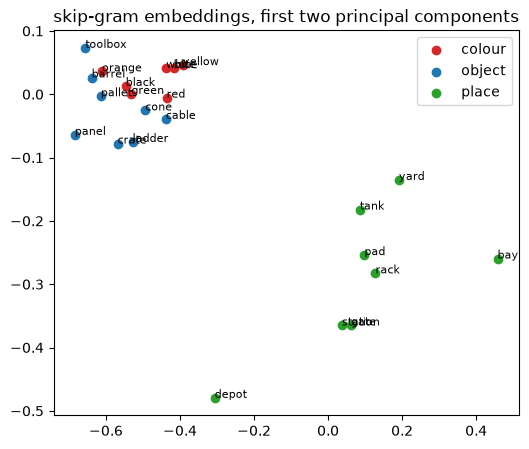

In [5]:
U, S, Vh = torch.linalg.svd(E - E.mean(0))           # PCA by SVD of centred embeddings
xy = (E - E.mean(0)) @ Vh[:2].T
groups = {"colour": COLORS, "object": [o.split()[0] for o in OBJECTS],
          "place": ["yard", "bay", "station", "pad", "gate", "depot", "rack", "tank"]}
fig, ax = plt.subplots(figsize=(6, 5))
for (name, ws), c in zip(groups.items(), ["tab:red", "tab:blue", "tab:green"]):
    idx = [stoi[w] for w in ws if w in stoi]
    ax.scatter(xy[idx, 0], xy[idx, 1], c=c, label=name)
    for i in idx:
        ax.annotate(itos[i], xy[i].tolist(), fontsize=8)
ax.legend(); ax.set_title("skip-gram embeddings, first two principal components"); plt.show()

The model was never told what a colour is. Colours cluster because they fill the same slot in
`"the ___ toolbox"` — the distributional hypothesis. Note what is *not* learned: nothing about what red
looks like, or how heavy a toolbox is (the grounding problem, book 1.3).

## 3. Vanishing and exploding gradients in an RNN

$\mathbf h_t=\tanh(\mathbf x_tW_x+\mathbf h_{t-1}W_h)$. We measure $\lVert\partial\mathbf h_t/\partial\mathbf h_0\rVert$
(spectral norm of the Jacobian, computed with autograd) for recurrent matrices of different scales.

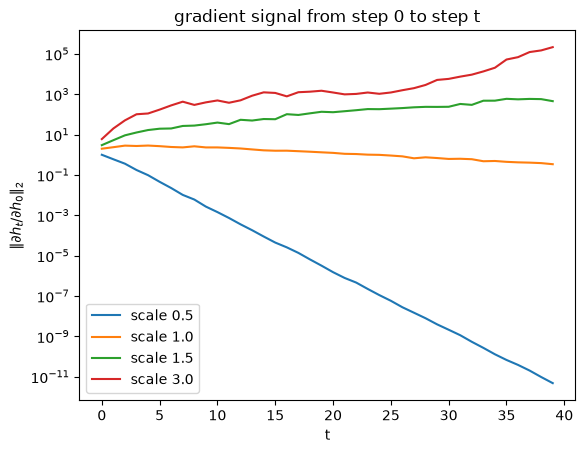

In [6]:
def jacobian_norms(scale, T=40, d=32, seed=0):
    set_seed(seed)
    W_h = torch.randn(d, d) / math.sqrt(d) * scale       # spectral radius ≈ scale
    W_x = torch.randn(d, d) / math.sqrt(d)
    xs = torch.randn(T, d) * 0.1
    h0 = torch.zeros(d, requires_grad=True)
    h, norms = h0, []
    for t in range(T):
        h = torch.tanh(xs[t] @ W_x + h @ W_h)
        J = torch.autograd.functional.jacobian(lambda h0_: _roll(h0_, xs[:t + 1], W_x, W_h), h0)
        norms.append(torch.linalg.matrix_norm(J, ord=2).item())
    return norms


def _roll(h, xs, W_x, W_h):
    for x in xs:
        h = torch.tanh(x @ W_x + h @ W_h)
    return h


for scale in [0.5, 1.0, 1.5, 3.0]:
    plt.semilogy(jacobian_norms(scale), label=f"scale {scale}")
plt.xlabel("t"); plt.ylabel(r"$\|\partial h_t/\partial h_0\|_2$"); plt.legend()
plt.title("gradient signal from step 0 to step t"); plt.show()

Small recurrent weights: the signal decays geometrically (vanishing). Large ones: it first grows, then
tanh saturates and $1-\tanh^2\to0$ kills it too. Only a narrow band preserves information over long
spans — the problem gates (LSTM) and, later, residual connections and attention solve.

## 4. Sinusoidal positional encodings
$p_{t,2i}=\sin(t\omega_i)$, $p_{t,2i+1}=\cos(t\omega_i)$, $\omega_i=10000^{-2i/d}$.

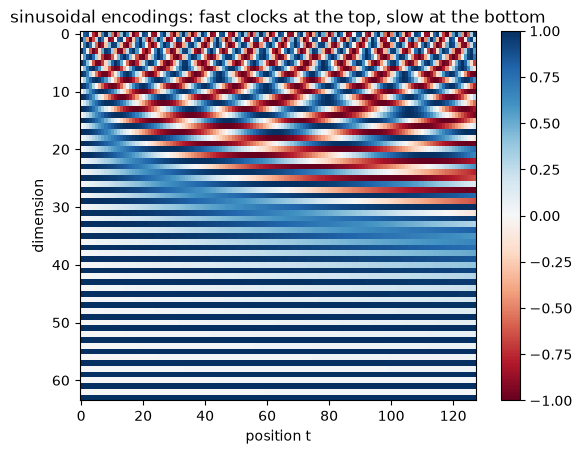

In [7]:
def sinusoidal(T, d, base=10000.0):
    omega = base ** (-torch.arange(0, d, 2).float() / d)        # (d/2,)
    ang = torch.arange(T).float()[:, None] * omega              # (T, d/2)
    pe = torch.zeros(T, d)
    pe[:, 0::2], pe[:, 1::2] = ang.sin(), ang.cos()
    return pe


pe = sinusoidal(128, 64)
plt.imshow(pe.T, aspect="auto", cmap="RdBu"); plt.xlabel("position t"); plt.ylabel("dimension")
plt.colorbar(); plt.title("sinusoidal encodings: fast clocks at the top, slow at the bottom"); plt.show()

**Shifting by $k$ is a fixed linear map.** For each pair $(\sin t\omega, \cos t\omega)$ the shift is a
rotation by $k\omega$ that does not depend on $t$. Build the block-diagonal map for $k=5$ and check it
sends $\mathbf p_t$ to $\mathbf p_{t+5}$ for every $t$.

In [8]:
k, d = 5, 64
omega = 10000 ** (-torch.arange(0, d, 2).float() / d)
M = torch.zeros(d, d)
for i, w in enumerate(omega):
    c, s = math.cos(k * w), math.sin(k * w)
    M[2 * i:2 * i + 2, 2 * i:2 * i + 2] = torch.tensor([[c, -s], [s, c]])   # row-vector convention
err = (pe[:-k] @ M - pe[k:]).abs().max().item()
print(f"max |p_t M - p_(t+5)| = {err:.2e}")
assert err < 1e-4

max |p_t M - p_(t+5)| = 5.03e-06


## 5. Rotary position embedding (RoPE)
Rotate each pair $(2i, 2i+1)$ of a query/key at position $m$ by angle $m\theta_i$. Then
$\tilde{\mathbf q}_m\tilde{\mathbf k}_n^\top$ depends only on $m-n$.

In [9]:
def rope(x, positions, base=10000.0):
    """x: (T, d_h); positions: (T,). Interleaved-pair layout, as in the RoFormer paper."""
    d_h = x.shape[-1]
    theta = base ** (-torch.arange(0, d_h, 2).float() / d_h)    # (d_h/2,)
    ang = positions.float()[:, None] * theta                    # (T, d_h/2)
    cos, sin = ang.cos(), ang.sin()
    x1, x2 = x[..., 0::2], x[..., 1::2]
    out = torch.empty_like(x)
    out[..., 0::2] = x1 * cos - x2 * sin
    out[..., 1::2] = x1 * sin + x2 * cos
    return out


q, k_ = torch.randn(1, 64), torch.randn(1, 64)
for m, n in [(3, 1), (10, 8), (100, 98), (7, 7), (12, 12)]:
    s = (rope(q, torch.tensor([m])) @ rope(k_, torch.tensor([n])).T).item()
    print(f"m={m:3d} n={n:3d} m-n={m - n}: score {s:+.5f}")
print("no rotation (m=n): ", (q @ k_.T).item())

m=  3 n=  1 m-n=2: score -17.86818
m= 10 n=  8 m-n=2: score -17.86819
m=100 n= 98 m-n=2: score -17.86819
m=  7 n=  7 m-n=0: score -17.58419
m= 12 n= 12 m-n=0: score -17.58419
no rotation (m=n):  -17.58419418334961


Scores for equal offsets agree (to float precision), and $m=n$ recovers the unrotated dot product.
Rotations preserve norms, so RoPE changes only *angles* between queries and keys.

In [10]:
assert torch.allclose(rope(q, torch.tensor([40])).norm(), q.norm())

## Exercises
1. Re-train the skip-gram with $d=2$ and plot the embeddings directly. Which distinctions survive?
2. Replace the tanh RNN by an LSTM (`nn.LSTMCell`) and repeat the Jacobian experiment.
3. Implement the "rotate-half" RoPE layout (pairs $(i, i+d_h/2)$) and show it also has the relative
   property, but that a query rotated with one layout and a key with the other does not.
4. For a multi-robot coordinator that reads one token per robot, write a test that checks whether a
   model is permutation-equivariant in the robots. Apply it to a transformer with and without learned
   positional embeddings (you can use `vlacourse.transformer.Block`).